# KNN y escalas: cómo las unidades cambian los vecinos

**Pregunta:** si queremos predecir si una persona necesita una plaza de garaje adicional, ¿debería pesar más una diferencia de 100 € de ingresos que una diferencia de cuatro coches?

Veremos el efecto en tres pasos: un cálculo de distancias, un mapa de decisiones con **240 personas** y una evaluación sobre personas que el modelo no ha visto al entrenar.

**Variables:** ingresos anuales en euros y número de coches. **Objetivo:** 0 = no necesita plaza adicional; 1 = sí necesita.

> Los datos y la etiqueta son **ficticios**. Hemos diseñado la etiqueta para que dependa sobre todo de los coches; los ingresos no aportan información por construcción. Así podemos aislar el problema de las escalas. No estamos formulando una regla real sobre aparcamiento.

## 1. Un conjunto suficientemente grande para ver el patrón

Generamos 240 perfiles con una semilla fija. La etiqueta es «sí» cuando hay tres o más coches, salvo aproximadamente un 8 % de casos invertidos para simular factores no observados. Separamos entrenamiento y prueba **antes** de calcular cualquier escala. La prueba servirá para evaluar si el patrón se mantiene fuera de la muestra de entrenamiento. Las primeras tablas muestran solo los datos de entrenamiento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(42)
n = 240
X = pd.DataFrame({
    "ingresos": rng.integers(20_000, 90_001, size=n),
    "coches": rng.integers(0, 5, size=n),
})
y = pd.Series((X["coches"] >= 3).astype(int), name="necesita_plaza_extra")
indices_ruido = rng.choice(n, size=round(0.08 * n), replace=False)
y.iloc[indices_ruido] = 1 - y.iloc[indices_ruido]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print(f"Perfiles: {len(X)} | entrenamiento: {len(X_train)} | prueba: {len(X_test)}")
display(X_train.assign(necesita_plaza_extra=y_train.map({0: "No", 1: "Sí"})).head(10))
proporcion = pd.crosstab(X_train["coches"], y_train, normalize="index").round(2)
proporcion.columns = ["No", "Sí"]
display(proporcion.rename_axis("Número de coches"))

Perfiles: 240 | entrenamiento: 168 | prueba: 72


,ingresos,coches,necesita_plaza_extra
0,50246,0,No
1,80081,2,No
2,66334,4,Sí
3,67859,0,No
4,79856,0,No
5,55073,2,Sí
6,26592,0,No
7,26135,0,No
8,72037,1,No
9,33263,3,Sí


,No,Sí
Número de coches,,
0,1.00,0.00
1,0.93,0.07
2,0.95,0.05
3,0.06,0.94
4,0.13,0.87


## 2. La causa: qué suma realmente la distancia

KNN usa aquí la distancia euclídea. Para dos perfiles, eleva al cuadrado la diferencia de ingresos **en euros** y la diferencia de coches, suma ambas cantidades y calcula la raíz:

$$d(a,b)=\sqrt{(\Delta\text{ingresos})^2+(\Delta\text{coches})^2}$$

Comparemos una consulta de 30.000 € y cuatro coches con dos perfiles ilustrativos. El primero gana casi lo mismo, pero no tiene coches. El segundo tiene cuatro coches, aunque gana 6.000 € más. Estos dos perfiles solo sirven para hacer visible el cálculo; el experimento posterior utiliza los 240 datos generados, con 168 para entrenamiento y 72 para prueba.

In [2]:
referencia = pd.DataFrame({"ingresos": [30_000], "coches": [4]})
candidatos = pd.DataFrame(
    {"ingresos": [30_100, 36_000], "coches": [0, 4]},
    index=["Ingreso parecido, 0 coches", "Mismos coches, ingreso distinto"],
)
escalador_demo = StandardScaler().fit(X_train)  # Solo aprende del entrenamiento
diferencias = candidatos.to_numpy() - referencia.to_numpy()
calculo = candidatos.copy()
calculo["Δ ingresos (€)"] = np.abs(diferencias[:, 0]).astype(int)
calculo["Δ coches"] = np.abs(diferencias[:, 1]).astype(int)
calculo["distancia en bruto"] = np.linalg.norm(diferencias, axis=1).round(2)
calculo["distancia tras estandarizar"] = np.linalg.norm(
    diferencias / escalador_demo.scale_, axis=1
).round(3)
print("Desviación típica aprendida en entrenamiento:",
      dict(zip(X_train.columns, escalador_demo.scale_.round(2))))
display(calculo)

Desviación típica aprendida en entrenamiento: {'ingresos': np.float64(19224.51), 'coches': np.float64(1.43)}


,ingresos,coches,Δ ingresos (€),Δ coches,distancia en bruto,distancia tras estandarizar
"Ingreso parecido, 0 coches",30100,0,100,4,100.08,2.793
"Mismos coches, ingreso distinto",36000,4,6000,0,6000.00,0.312


**Observa el orden:** en bruto, 100 € frente a 6.000 € decide casi toda la distancia. Al estandarizar cada columna mediante $z=(x-\mu)/\sigma$, cada diferencia se expresa en desviaciones típicas de **su propia variable**. La resta entre dos valores estandarizados equivale a dividir su diferencia por la desviación típica de esa columna. El segundo perfil pasa a estar más cerca.

Esto no hace que ambas variables sean igual de útiles para predecir; solo elimina el peso arbitrario de sus unidades. El escalador aprende media y desviación típica con entrenamiento y reutiliza esos valores para datos nuevos.

## 3. Dos KNN, la misma partición y el mismo número de vecinos

Usamos $k=9$ para ambos modelos. El segundo incluye StandardScaler dentro de un Pipeline, de modo que el escalador se ajusta exclusivamente con el conjunto de entrenamiento. La exactitud de prueba se calcula con los 72 perfiles reservados y se compara con predecir siempre la clase mayoritaria.

In [3]:
k = 9
modelo_sin = KNeighborsClassifier(n_neighbors=k)
modelo_con = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
modelo_sin.fit(X_train, y_train)
modelo_con.fit(X_train, y_train)

pred_test_sin = modelo_sin.predict(X_test)
pred_test_con = modelo_con.predict(X_test)
acierto_sin = accuracy_score(y_test, pred_test_sin)
acierto_con = accuracy_score(y_test, pred_test_con)
clase_mayoritaria = y_train.mode().iloc[0]
acierto_base = accuracy_score(y_test, np.full(len(y_test), clase_mayoritaria))

display(pd.DataFrame({
    "Método": ["Clase mayoritaria", "KNN sin escalar", "KNN con StandardScaler"],
    "Exactitud en prueba": [acierto_base, acierto_sin, acierto_con],
}).round(3))

,Método,Exactitud en prueba
0,Clase mayoritaria,0.639
1,KNN sin escalar,0.653
2,KNN con StandardScaler,0.875


## 4. ¿Es un caso aislado? Probamos una rejilla de 25 consultas

La rejilla se define **antes** de mirar las predicciones: cinco niveles de ingresos por cinco cantidades de coches. Mostramos las 25 respuestas y contamos cuántas cambian. Para inspeccionar vecinos, elegimos de forma explícita la primera discrepancia entre los casos con cuatro coches; si no la hubiera, tomamos la primera discrepancia de la rejilla.

In [4]:
consultas = pd.MultiIndex.from_product(
    [[25_000, 40_000, 55_000, 70_000, 85_000], range(5)],
    names=["ingresos", "coches"],
).to_frame(index=False)
comparacion = consultas.copy()
comparacion["sin escalar"] = modelo_sin.predict(consultas)
comparacion["estandarizado"] = modelo_con.predict(consultas)
comparacion["cambia"] = comparacion["sin escalar"] != comparacion["estandarizado"]
print(f"Cambian {comparacion['cambia'].sum()} de {len(comparacion)} consultas.")
display(comparacion.assign(**{
    "sin escalar": comparacion["sin escalar"].map({0: "No", 1: "Sí"}),
    "estandarizado": comparacion["estandarizado"].map({0: "No", 1: "Sí"}),
}))

cambios = comparacion.loc[comparacion["cambia"]]
preferidos = cambios.loc[cambios["coches"] == 4]
ejemplo = preferidos if len(preferidos) else cambios
fila = ejemplo.iloc[0] if len(ejemplo) else comparacion.iloc[0]
nuevo = pd.DataFrame({
    "ingresos": [int(fila["ingresos"])],
    "coches": [int(fila["coches"])],
})
print("Consulta que ampliaremos en el gráfico:", nuevo.iloc[0].to_dict())

Cambian 11 de 25 consultas.


,ingresos,coches,sin escalar,estandarizado,cambia
0,25000,0,No,No,False
1,25000,1,No,No,False
2,25000,2,No,No,False
3,25000,3,No,Sí,True
4,25000,4,No,Sí,True
5,40000,0,No,No,False
6,40000,1,No,No,False
7,40000,2,No,No,False
8,40000,3,No,Sí,True
9,40000,4,No,Sí,True


Consulta que ampliaremos en el gráfico: {'ingresos': 25000, 'coches': 4}


## 5. Mapa de decisiones: mismos ejes, regiones diferentes

Cada franja horizontal representa una cantidad **entera** de coches. El color de fondo indica la predicción para cada ingreso; los puntos son ejemplos de entrenamiento. Los círculos negros señalan los nueve vecinos de la consulta marcada con una estrella. Los dos paneles usan los mismos ejes y los mismos datos originales.

La pequeña variación vertical de los puntos solo evita solapamientos en el dibujo: **KNN recibe los valores enteros originales**. La distancia física entre puntos en el papel no equivale a la distancia euclídea del modelo, porque las unidades de los ejes son distintas; la tabla de la sección siguiente da las distancias calculadas.

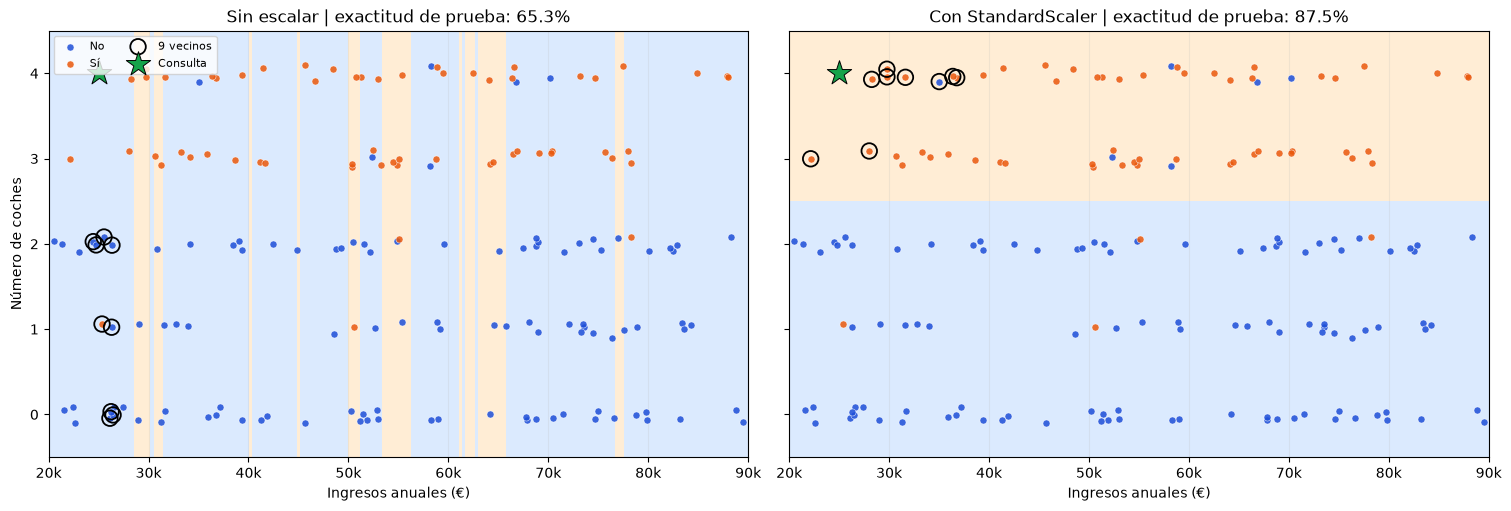

In [5]:
escalador = modelo_con.named_steps["standardscaler"]
knn_con = modelo_con.named_steps["kneighborsclassifier"]
dist_sin, idx_sin = modelo_sin.kneighbors(nuevo)
dist_con, idx_con = knn_con.kneighbors(escalador.transform(nuevo))

ingresos_mapa = np.linspace(20_000, 90_000, 220)
rejilla_mapa = pd.MultiIndex.from_product(
    [range(5), ingresos_mapa], names=["coches", "ingresos"]
).to_frame(index=False)[["ingresos", "coches"]]
jitter = np.random.default_rng(123).uniform(-0.10, 0.10, size=len(X_train))
colores_fondo = ListedColormap(["#dbeafe", "#ffedd5"])
colores_puntos = {0: "#1d4ed8", 1: "#ea580c"}

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True,
                        constrained_layout=True)
for ax, modelo, indices, titulo, acierto in [
    (axs[0], modelo_sin, idx_sin[0], "Sin escalar", acierto_sin),
    (axs[1], modelo_con, idx_con[0], "Con StandardScaler", acierto_con),
]:
    pred_mapa = modelo.predict(rejilla_mapa).reshape(5, len(ingresos_mapa))
    ax.imshow(pred_mapa, origin="lower", aspect="auto", interpolation="nearest",
              extent=[20_000, 90_000, -0.5, 4.5], cmap=colores_fondo,
              vmin=0, vmax=1)
    for clase, nombre in [(0, "No"), (1, "Sí")]:
        mascara = y_train.eq(clase).to_numpy()
        ax.scatter(X_train.loc[mascara, "ingresos"],
                   X_train.loc[mascara, "coches"] + jitter[mascara],
                   s=26, c=colores_puntos[clase], edgecolors="white",
                   linewidths=0.4, alpha=0.85, label=nombre, zorder=3)
    ax.scatter(X_train.iloc[indices]["ingresos"],
               X_train.iloc[indices]["coches"] + jitter[indices],
               s=125, facecolors="none", edgecolors="black",
               linewidths=1.3, label=f"{k} vecinos", zorder=4)
    ax.scatter(nuevo.iloc[0]["ingresos"], nuevo.iloc[0]["coches"],
               marker="*", s=340, c="#16a34a", edgecolors="black",
               linewidths=0.7, label="Consulta", zorder=5)
    ax.set(title=f"{titulo} | exactitud de prueba: {acierto:.1%}",
           xlabel="Ingresos anuales (€)", xlim=(20_000, 90_000),
           ylim=(-0.5, 4.5), yticks=range(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor / 1000:.0f}k"))
    ax.grid(axis="x", alpha=0.18)
axs[0].set_ylabel("Número de coches")
axs[0].legend(loc="upper left", ncol=2, fontsize=8)
plt.show()

## 6. Vecinos concretos de la misma consulta

Aquí se ve qué perfiles votan en cada modelo. La distancia de la columna derecha está en euros y coches mezclados en el primer modelo, y en unidades estandarizadas en el segundo. **No compares sus números absolutos entre las dos tablas**; compara el orden de vecinos y sus clases.

In [6]:
def tabla_vecinos(distancias, indices):
    vecinos = X_train.iloc[indices[0]].reset_index(drop=True).copy()
    vecinos.insert(0, "posición", np.arange(1, len(vecinos) + 1))
    vecinos["necesita plaza"] = y_train.iloc[indices[0]].map(
        {0: "No", 1: "Sí"}
    ).to_numpy()
    vecinos["distancia"] = np.round(distancias[0], 3)
    return vecinos

print("Consulta:", nuevo.iloc[0].to_dict())
print("Sin escalar →", "Sí" if modelo_sin.predict(nuevo)[0] else "No")
display(tabla_vecinos(dist_sin, idx_sin))
print("Con StandardScaler →", "Sí" if modelo_con.predict(nuevo)[0] else "No")
display(tabla_vecinos(dist_con, idx_con))

Consulta: {'ingresos': 25000, 'coches': 4}
Sin escalar → No


,posición,ingresos,coches,necesita plaza,distancia
0,1,24754,2,No,246.008
1,2,25344,1,Sí,344.013
2,3,24467,2,No,533.004
3,4,25543,2,No,543.004
4,5,26135,0,No,1135.007
5,6,26247,0,No,1247.006
6,7,26303,1,No,1303.003
7,8,26339,2,No,1339.001
8,9,26449,0,No,1449.006


Con StandardScaler → Sí


,posición,ingresos,coches,necesita plaza,distancia
0,1,28260,4,Sí,0.170
1,2,29782,4,Sí,0.249
2,3,29785,4,Sí,0.249
3,4,31635,4,Sí,0.345
4,5,35021,4,No,0.521
5,6,36375,4,Sí,0.592
6,7,36769,4,Sí,0.612
7,8,22157,3,Sí,0.714
8,9,28017,3,Sí,0.716


## 7. Un experimento de unidades: euros frente a miles de euros

Dividir todos los ingresos por 1.000 solo cambia la **unidad**, no la información. Volvemos a ajustar ambos modelos con exactamente las mismas filas de entrenamiento y prueba. Un KNN sin escalar puede cambiar sus vecinos y predicciones; con StandardScaler la transformación es equivalente y sus predicciones deberían mantenerse. **Antes de ejecutar la siguiente celda, predice cuál de los dos cambiará más.**

In [7]:
X_train_miles = X_train.assign(ingresos=X_train["ingresos"] / 1000)
X_test_miles = X_test.assign(ingresos=X_test["ingresos"] / 1000)

modelo_sin_miles = KNeighborsClassifier(n_neighbors=k).fit(X_train_miles, y_train)
modelo_con_miles = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=k)
).fit(X_train_miles, y_train)
pred_sin_miles = modelo_sin_miles.predict(X_test_miles)
pred_con_miles = modelo_con_miles.predict(X_test_miles)

display(pd.DataFrame({
    "Modelo": ["KNN sin escalar", "KNN con StandardScaler"],
    "Exactitud en €": [acierto_sin, acierto_con],
    "Exactitud en miles de €": [
        accuracy_score(y_test, pred_sin_miles),
        accuracy_score(y_test, pred_con_miles),
    ],
    "Predicciones de prueba que cambian": [
        np.count_nonzero(pred_test_sin != pred_sin_miles),
        np.count_nonzero(pred_test_con != pred_con_miles),
    ],
}).round(3))

,Modelo,Exactitud en €,Exactitud en miles de €,Predicciones de prueba que cambian
0,KNN sin escalar,0.653,0.764,20
1,KNN con StandardScaler,0.875,0.875,0


## Para comprobar que lo has entendido

1. Usa la última tabla para explicar por qué uno de los modelos cambia más al pasar de euros a miles de euros.
2. Cambia $k=9$ por $k=3$ y después por $k=15$. ¿Cómo cambian el mapa y la exactitud de prueba?
3. Prueba una consulta de dos coches y 55.000 €. Busca sus vecinos en ambos modelos y explica sus votos.
4. ¿Por qué el escalador se ajusta con entrenamiento y nunca con la prueba?
5. Si en otros datos los ingresos sí aportaran información, ¿seguiría siendo necesariamente mejor el modelo estandarizado?

**Idea clave:** KNN decide por distancias. Estandarizar evita que una variable domine solo por sus unidades; que mejore la predicción depende de los datos y se comprueba con un conjunto de prueba.